# Prediction case review - three fixed training seeds

CPU only. Reuses saved predictions; no model or detector inference, training, or threshold fitting.

Run all cells in a fresh Colab session. The default selects at most 24 illustrative image-attribute pairs:
four conditions x six outcome/landmark strata. Empty strata are documented, never silently replaced.
Both successful and unsuccessful classifier outcomes are included. Selection is outcome-stratified and
must not be used to infer prevalence or causality. All twelve model runs and both F1 decision rules are shown.

Requirements: the completed benchmark archive and its original prediction shards remain on Drive.
Pillow must be 11.3.0, as in the frozen benchmark. This notebook does not change dependencies automatically.
If interrupted, reconnect and Run all; completed condition selections are verified and reused.
Use only one running writer. Settings changes require a new output directory.

This covers the case-review portion of October 23. Fresh-environment model inference and the final research
release are separate steps; this notebook does not claim they have been completed.


In [1]:
from google.colab import drive
from pathlib import Path
import PIL

drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/FacialVisualProfile')
OUTPUT = PROJECT / 'runs/benchmark/prediction_case_review_v1'
CONDITIONS = ('clean_s0', 'blur_s4', 'rotation_s4', 'occlusion_s4')
SELECTION_SEED = 20261016
assert PROJECT.is_dir(), f'Missing project: {PROJECT}'
assert PIL.__version__ == '11.3.0', (
    f'Frozen image reproduction requires Pillow 11.3.0; current {PIL.__version__}. '
    'Install that version in a separate cell, restart the session, then Run all.'
)
print('CPU case review; no GPU required')
print('Output:', OUTPUT)


Mounted at /content/drive
CPU case review; no GPU required
Output: /content/drive/MyDrive/FacialVisualProfile/runs/benchmark/prediction_case_review_v1


In [2]:
%%writefile /content/review_prediction_cases.py
#!/usr/bin/env python3
"""CPU case review from archived predictions; no model or detector inference."""
from pathlib import Path
from collections import Counter
import csv
import hashlib
import io
import json
import platform
import time
import zipfile

import numpy as np
from sklearn.metrics import average_precision_score
from threadpoolctl import threadpool_limits

MODELS = ('r18', 'r50', 'm3', 'oracle')
RUNS = tuple(f'{m}_seed{s}' for s in range(3) for m in MODELS)
PAIRS = (('m3', 'r18'), ('m3', 'r50'), ('oracle', 'm3'), ('r50', 'r18'))
RULES = ('frozen_thresholds', 'fixed_0_5')
GROUPS = ('nme_le_5_percent', 'nme_5_to_10_percent', 'nme_10_to_20_percent',
          'nme_gt_20_percent', 'detection_failure')
ARCHIVE_SHA = '4c0cece5d688bbe87bb490c7f4c2429059a6ab40dae9c84b5cfd19ecb4baf45c'


def check(ok, message):
    if not ok:
        raise ValueError(message)


def sha(data):
    return hashlib.sha256(data).hexdigest()


def encode(value):
    return (json.dumps(value, sort_keys=True, indent=2, allow_nan=False)+'\n').encode()


def atomic(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        check(path.read_bytes() == data, f'Existing file differs; preserved: {path}')
        return
    temporary = path.with_name(path.name+'.partial')
    temporary.write_bytes(data)
    temporary.replace(path)


def write_csv(path, rows):
    stream = io.StringIO(newline='')
    writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
    atomic(path, stream.getvalue().encode())


def sigmoid(values):
    values = values.astype(np.float64)
    p = np.empty_like(values)
    positive = values >= 0
    p[positive] = 1/(1+np.exp(-values[positive]))
    ex = np.exp(values[~positive])
    p[~positive] = ex/(1+ex)
    return p


def read_shard(path, expected_hash, expected_binding, condition):
    data = path.read_bytes()
    check(sha(data) == expected_hash, f'Shard SHA256 mismatch: {path}')
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        names = archive.namelist()
        members = set(names)
        standard = {'manifest.json', 'records.json', 'predictions.npz'}
        oracle_schema = {'manifest.json', 'predictions.npz'}
        check(len(names) == len(members) and members in (standard, oracle_schema), f'Shard members differ: {path}')
        is_oracle = members == oracle_schema
        manifest = json.loads(archive.read('manifest.json'))
        check(manifest['binding_sha256'] == expected_binding, 'Shard execution binding mismatch')
        check(manifest['condition'] == condition, 'Shard condition mismatch')
        check(set(manifest['files']) == members - {'manifest.json'}, 'Shard payload names differ')
        parts = {name: archive.read(name) for name in manifest['files']}
        for name, payload in parts.items():
            check(sha(payload) == manifest['files'][name], f'Inner hash mismatch: {path}/{name}')
    with np.load(io.BytesIO(parts['predictions.npz']), allow_pickle=False) as saved:
        arrays = {key: saved[key].copy() for key in saved.files}
    if is_oracle:
        # Day21 stores pairing metadata in NPZ arrays, not records.json.
        expected_keys = {'filenames', 'targets', 'oracle_logits', 'geometry_valid',
                         'gt_normalized_points', 'gt_pixels', 'final_rgb_sha256'}
        check(set(arrays) == expected_keys, 'Day21 Oracle NPZ schema differs')
        n = len(arrays['filenames'])
        check(arrays['filenames'].shape == (n,) and arrays['filenames'].dtype.kind == 'U', 'Invalid Oracle names')
        check(arrays['targets'].shape == (n,24) and arrays['targets'].dtype == np.float32, 'Invalid Oracle targets')
        check(np.isin(arrays['targets'], [0,1]).all(), 'Oracle targets are not binary')
        check(arrays['oracle_logits'].shape == (n,24) and arrays['oracle_logits'].dtype == np.float32 and np.isfinite(arrays['oracle_logits']).all(), 'Invalid Oracle logits')
        check(arrays['geometry_valid'].shape == (n,) and arrays['geometry_valid'].dtype == np.bool_ and arrays['geometry_valid'].all(), 'Oracle GT must be valid for every sample')
        check(arrays['gt_pixels'].shape == (n,5,2) and arrays['gt_pixels'].dtype == np.float64 and np.isfinite(arrays['gt_pixels']).all(), 'Invalid Oracle pixel GT')
        check(arrays['gt_normalized_points'].shape == (n,10) and arrays['gt_normalized_points'].dtype == np.float32 and np.isfinite(arrays['gt_normalized_points']).all(), 'Invalid Oracle normalized GT')
        check(arrays['final_rgb_sha256'].shape == (n,) and arrays['final_rgb_sha256'].dtype.kind == 'U', 'Invalid Oracle RGB hashes')
        check(all(len(x)==64 and all(c in '0123456789abcdef' for c in x) for x in arrays['final_rgb_sha256'].tolist()), 'Malformed Oracle RGB hash')
        check(isinstance(manifest.get('reference_shard_sha256'),str) and len(manifest['reference_shard_sha256'])==64, 'Missing Oracle reference-shard binding')
        # Create a read-only metadata view from checksum-verified NPZ arrays.
        records = [dict(sample_id=str(arrays['filenames'][i]), condition=condition['condition'],
                        severity=condition['severity'], final_rgb_sha256=str(arrays['final_rgb_sha256'][i]),
                        gt_pixels=arrays['gt_pixels'][i].tolist()) for i in range(n)]
    else:
        records = json.loads(parts['records.json'])
    return arrays, records, manifest


def metric_values(targets, probabilities, thresholds):
    pred = probabilities >= np.asarray(thresholds)
    tp = (pred & (targets == 1)).sum(axis=0)
    denom = pred.sum(axis=0) + targets.sum(axis=0)
    f1 = np.divide(2*tp, denom, out=np.zeros(24, dtype=float), where=denom > 0)
    positives = targets.sum(axis=0)
    ap = np.array([float(average_precision_score(targets[:,i], probabilities[:,i]))
                   if positives[i] else 0.0 for i in range(24)])
    return f1, ap, positives


def setup(project, output, source_code, labels, selection_seed):
    project, output = Path(project), Path(output)
    base = project/'runs/benchmark'
    multi = base/'multiseed_seed1_seed2'
    archive_data = (multi/'seed1_seed2_test_results_archive.zip').read_bytes()
    check(sha(archive_data) == ARCHIVE_SHA, 'Input archive differs from the completed frozen test archive')
    with zipfile.ZipFile(io.BytesIO(archive_data)) as archive:
        manifest = json.loads(archive.read('archive_manifest.json'))
        for name, digest in manifest['files'].items():
            check(sha(archive.read(name)) == digest, f'Archive hash mismatch: {name}')
        new_report = json.loads(archive.read('multiseed_benchmark_report.json'))
        oracle_report = json.loads(archive.read('source/seed0_oracle_report.json'))
        binding = json.loads(archive.read('execution_binding.json'))
    check(new_report['full_benchmark_complete'] is True, 'Formal benchmark incomplete')
    check(new_report['threshold_fitting_performed'] is False, 'Unexpected threshold fitting')
    old_reports, hashes = {}, {}
    for day in ('day19','day20'):
        for name, digest in binding['source_reports'][day].items():
            data = (base/day/name).read_bytes()
            check(sha(data) == digest, f'Seed0 report/binding differs: {day}/{name}')
            hashes[f'{day}/{name}'] = digest
            if name.endswith('_benchmark_report.json'):
                old_reports[day] = json.loads(data)
    first_binding = json.loads((base/'day19/execution_binding.json').read_bytes())
    partition_bytes = (project/'data/list_eval_partition.txt').read_bytes()
    check(sha(partition_bytes) == first_binding['annotation_sha256']['list_eval_partition.txt'], 'Partition file changed')
    names = [row.split()[0] for row in partition_bytes.decode('utf-8-sig').splitlines() if row.split()[1]=='2']
    check(len(names) == len(set(names)) == 19962, 'Official test IDs differ')
    attributes = new_report['attribute_names']
    check(len(attributes) == 24 and attributes == oracle_report['attribute_names'], 'Attribute order mismatch')
    attr_bytes = (project/'data/list_attr_celeba.txt').read_bytes()
    check(sha(attr_bytes) == first_binding['annotation_sha256']['list_attr_celeba.txt'], 'Attribute annotations changed')
    lines = attr_bytes.decode('utf-8-sig').splitlines()
    header = lines[1].split()
    columns = [header.index(a) for a in attributes]
    needed = set(names)
    labels = {}
    for line in lines[2:]:
        fields = line.split()
        if fields[0] in needed:
            labels[fields[0]] = [int(fields[1+i]) == 1 for i in columns]
    targets = np.asarray([labels[n] for n in names], dtype=np.uint8)
    reports = [*old_reports.values(), oracle_report, new_report]
    expected = {}
    for report in reports:
        check(report['attribute_names'] == attributes, 'Report attribute order differs')
        for entry in report['conditions']:
            c = entry['condition']; label = f"{c['condition']}_s{c['severity']}"
            for run, metrics in entry['models'].items():
                check((label,run) not in expected, 'Duplicate expected metrics')
                expected[label,run] = metrics
    conditions = binding['conditions']
    check(len(conditions)==21 and len(expected)==252, 'Expected 21 conditions and 252 overall rows')
    # Freeze the existing threshold vectors and check they do not change with corruption.
    thresholds = {}
    for run in RUNS:
        thresholds[run] = expected['clean_s0',run]['frozen_thresholds']['thresholds']
        check(len(thresholds[run])==24, 'Threshold count differs')
        for condition in conditions:
            label = f"{condition['condition']}_s{condition['severity']}"
            check(expected[label,run]['frozen_thresholds']['thresholds']==thresholds[run], 'Thresholds changed across conditions')
            check(expected[label,run]['fixed_0_5']['thresholds']==[0.5]*24, 'Fixed threshold differs')
    import PIL
    protocol = dict(archive_sha256=ARCHIVE_SHA, source_report_hashes=hashes,
                    analysis_source_sha256=sha(source_code.encode()),
                    conditions=list(labels), selection_seed=selection_seed,
                    selection_rule='one image-attribute pair per category; at least two of three seeds where specified; deterministic seeded selection; unique images within condition',
                    numpy_version=np.__version__, pillow_version=PIL.__version__,
                    categories=['m3_right_r18_wrong','m3_wrong_r18_right','all_four_wrong','all_four_correct','high_nme_disagreement','detection_failure'],
                    outcome_rule='per-model clean-validation frozen thresholds',
                    inference=False, training=False, threshold_fitting=False,
                    causal_interpretation=False)
    signature = sha(encode(protocol))
    atomic(output/'analysis_binding.json', encode(protocol))
    atomic(output/'source/review_prediction_cases.py',source_code.encode())
    return dict(project=project, output=output, base=base, multi=multi, names=names, targets=targets,
                attributes=attributes, conditions=conditions, old_reports=old_reports,
                oracle_report=oracle_report, new_report=new_report, expected=expected,
                thresholds=thresholds, signature=signature)


def load_condition(ctx, condition):
    label = f"{condition['condition']}_s{condition['severity']}"
    day = 'day19' if condition['condition'] in ('clean','blur','brightness') else 'day20'
    old_report = ctx['old_reports'][day]
    parts = {run: [] for run in RUNS}
    group_parts, shard_audit = [], []
    maximum_nme_difference = 0.0
    for start in range(0,19962,256):
        stop = min(start+256,19962)
        relative = f'shards/{label}/{start:06d}_{stop:06d}.zip'
        old, records, old_manifest = read_shard(ctx['base']/day/relative, old_report['shard_sha256'][relative], old_report['execution_binding_sha256'],condition)
        oracle, oracle_records, oracle_manifest = read_shard(ctx['base']/'day21'/relative, ctx['oracle_report']['shard_sha256'][relative],ctx['oracle_report']['execution_binding_sha256'],condition)
        new, new_records, new_manifest = read_shard(ctx['multi']/relative,ctx['new_report']['shard_sha256'][relative],ctx['new_report']['execution_binding_sha256'],condition)
        check(oracle_manifest['reference_shard_sha256']==old_report['shard_sha256'][relative], 'Oracle manifest reference shard differs')
        check(new_manifest['source_shard_sha256']==old_report['shard_sha256'][relative], 'Multiseed source shard differs')
        reference_key = f'{day}/{relative}'
        check(ctx['oracle_report']['reference_shard_sha256'][reference_key]==old_report['shard_sha256'][relative], 'Oracle source shard differs')
        expected_names = ctx['names'][start:stop]
        for arrays in (old, oracle, new):
            check(arrays['filenames'].tolist()==expected_names, 'Paired image order differs')
            np.testing.assert_array_equal(arrays['targets'],ctx['targets'][start:stop])
        check(len(records)==len(oracle_records)==len(new_records)==stop-start, 'Record counts differ')
        np.testing.assert_allclose(oracle['gt_normalized_points'],new['gt_normalized_points'],rtol=0,atol=1e-6)
        np.testing.assert_array_equal(old['geometry_valid'],new['geometry_valid'])
        np.testing.assert_array_equal(old['predicted_normalized_points'],new['predicted_normalized_points'])
        groups=[]
        for i,record in enumerate(records):
            other, ore = new_records[i], oracle_records[i]
            for item in (record,other,ore):
                check(item['sample_id']==expected_names[i], 'Record ID differs')
                check(item['condition']==condition['condition'] and item['severity']==condition['severity'], 'Record condition differs')
                check(item['final_rgb_sha256']==record['final_rgb_sha256'], 'Paired RGB hash differs')
                np.testing.assert_allclose(item['gt_pixels'],record['gt_pixels'],rtol=0,atol=1e-9)
            valid=record['detection']['status']=='ok'
            check(bool(old['geometry_valid'][i])==valid, 'Detection mask differs')
            check(other['detection']==record['detection'] and other['nme']==record['nme'], 'Detector records differ')
            if valid:
                gt=np.asarray(record['gt_pixels'],dtype=float).reshape(5,2)
                points=np.asarray(record['detection']['landmarks'],dtype=float).reshape(5,2)
                eye=float(np.linalg.norm(gt[0]-gt[1]))
                check(eye>0 and np.isfinite(points).all(), 'Invalid NME inputs')
                nme=float(np.linalg.norm(points-gt,axis=1).mean()/eye)
                difference=abs(nme-record['nme'])
                check(difference<=1e-9,'NME reconstruction differs')
                maximum_nme_difference=max(maximum_nme_difference,difference)
                # Use the archived value for exact historical group boundaries.
                nme=record['nme']
                check(np.isfinite(nme) and nme>=0, 'Invalid archived NME')
                groups.append(0 if nme<=.05 else 1 if nme<=.10 else 2 if nme<=.20 else 3)
            else:
                check(record['nme'] is None, 'Failed detections must not have NME')
                check(not old['predicted_normalized_points'][i].any(), 'Invalid geometry must be zero')
                groups.append(4)
        group_parts.extend(groups)
        for run in RUNS:
            source=oracle if run=='oracle_seed0' else old if run.endswith('_seed0') else new
            key='oracle_logits' if run=='oracle_seed0' else run+'_logits'
            logits=source[key]
            check(logits.shape==(stop-start,24) and logits.dtype==np.float32 and np.isfinite(logits).all(),f'Invalid logits: {run}')
            parts[run].append(logits)
        shard_audit.append(relative)
        if (start//256+1)%20==0 or stop==19962:
            print(f'{label}: verified paired shard sets {start//256+1}/78',flush=True)
    return {run: sigmoid(np.concatenate(values)) for run,values in parts.items()}, np.asarray(group_parts), dict(paired_shard_sets=78, individual_shards=234, maximum_nme_difference=maximum_nme_difference)



CATEGORIES = ('m3_right_r18_wrong', 'm3_wrong_r18_right',
              'all_four_wrong', 'all_four_correct',
              'high_nme_disagreement', 'detection_failure')


def select_cases(ctx, condition, probabilities, groups, selection_seed):
    """Select illustrative pairs, without estimating population effects."""
    label = f"{condition['condition']}_s{condition['severity']}"
    y = ctx['targets'].astype(bool)
    correct = {}
    for model in MODELS:
        correct[model] = np.stack([
            (probabilities[f'{model}_seed{s}'] >= ctx['thresholds'][f'{model}_seed{s}']) == y
            for s in range(3)])
    help_votes = (correct['m3'] & ~correct['r18']).sum(axis=0)
    hurt_votes = (~correct['m3'] & correct['r18']).sum(axis=0)
    all_right = np.logical_and.reduce([correct[m] for m in MODELS]).sum(axis=0)
    all_wrong = np.logical_and.reduce([~correct[m] for m in MODELS]).sum(axis=0)
    disagree = np.logical_or(help_votes >= 2, hurt_votes >= 2)
    masks = (help_votes >= 2, hurt_votes >= 2, all_wrong >= 2, all_right >= 2,
             (groups[:, None] == 3) & disagree,
             np.broadcast_to(groups[:, None] == 4, y.shape))
    selected, coverage, used = [], [], set()
    for category, mask in zip(CATEGORIES, masks):
        candidates = np.argwhere(mask)
        counts = dict(category=category, eligible_pairs=int(mask.sum()),
                      eligible_images=int(np.any(mask, axis=1).sum()),
                      eligible_positive_pairs=int((mask & y).sum()),
                      eligible_negative_pairs=int((mask & ~y).sum()))
        seed = int.from_bytes(hashlib.sha256(
            f'{selection_seed}:{label}:{category}'.encode()).digest()[:8], 'little')
        rng = np.random.default_rng(seed)
        picked = None
        for index in rng.permutation(len(candidates)):
            row, col = map(int, candidates[index])
            if row not in used:
                picked = (row, col)
                break
        counts['selected'] = picked is not None
        counts['selection_status'] = 'selected' if picked is not None else ('no_eligible_pairs' if not len(candidates) else 'no_unused_images')
        coverage.append(counts)
        if picked is None:
            continue
        row, col = picked
        used.add(row)
        values = []
        for run in RUNS:
            p = float(probabilities[run][row, col])
            threshold = float(ctx['thresholds'][run][col])
            values.append(dict(run=run, probability=p, frozen_threshold=threshold,
                               predicted_frozen=int(p >= threshold),
                               predicted_at_0_5=int(p >= .5), target=int(y[row, col])))
        selected.append(dict(condition=label, category=category,
                             index=row, filename=ctx['names'][row],
                             attribute=ctx['attributes'][col], attribute_index=col,
                             target=int(y[row, col]), nme_group=GROUPS[int(groups[row])],
                             m3_right_r18_wrong_votes=int(help_votes[row, col]),
                             m3_wrong_r18_right_votes=int(hurt_votes[row, col]),
                             predictions=values))
    return selected, coverage


def verify_metrics(ctx, label, probabilities):
    for run in RUNS:
        p = probabilities[run]
        for rule in RULES:
            thresholds = ctx['thresholds'][run] if rule == 'frozen_thresholds' else [.5]*24
            f1, ap, _ = metric_values(ctx['targets'], p, thresholds)
            expected = ctx['expected'][label, run][rule]
            np.testing.assert_allclose(f1, expected['per_attribute_f1'], rtol=0, atol=1e-10)
            np.testing.assert_allclose(ap, expected['per_attribute_ap'], rtol=0, atol=1e-10)
            check(abs(f1.mean()-expected['macro_f1']) <= 1e-10, 'F1 reproduction failed')
            check(abs(ap.mean()-expected['map']) <= 1e-10, 'mAP reproduction failed')


def attach_records(ctx, condition, selected):
    """Read only the already-audited Seed0 metadata for selected cases."""
    label = f"{condition['condition']}_s{condition['severity']}"
    day = 'day19' if condition['condition'] in ('clean','blur','brightness') else 'day20'
    report = ctx['old_reports'][day]
    by_start = {}
    for case in selected:
        by_start.setdefault(case['index']//256*256, []).append(case)
    for start, cases in by_start.items():
        stop = min(start+256, 19962)
        rel = f'shards/{label}/{start:06d}_{stop:06d}.zip'
        arrays, records, _ = read_shard(ctx['base']/day/rel, report['shard_sha256'][rel],
                                       report['execution_binding_sha256'], condition)
        for case in cases:
            index = case['index']-start
            record = records[index]
            check(record['sample_id'] == case['filename'], 'Selected record ID differs')
            case['record'] = record
            case['source_shard'] = f'{day}/{rel}'
            case['source_shard_sha256'] = report['shard_sha256'][rel]
    return selected


def prepare_rendering(ctx):
    """Load exact frozen preprocessing functions in an isolated package."""
    import importlib.util
    import sys
    import types
    import PIL
    with zipfile.ZipFile(ctx['multi']/'seed1_seed2_test_results_archive.zip') as z:
        binding = json.loads(z.read('execution_binding.json'))
        frozen = z.read('source/day19_frozen_inputs.zip')
    check(sha(frozen) == binding['frozen_zip_sha256'], 'Frozen source ZIP differs')
    # Pillow is the renderer used to produce the frozen final RGB bytes.
    check(PIL.__version__ == binding['environment']['Pillow'],
          f"Use Pillow {binding['environment']['Pillow']} before running this notebook; current {PIL.__version__}")
    workspace = Path('/content/case_review_frozen_source')
    package_name = '_fvp_case_frozen'
    package = types.ModuleType(package_name)
    package.__path__ = [str(workspace)]
    sys.modules[package_name] = package
    with zipfile.ZipFile(io.BytesIO(frozen)) as z:
        manifest = json.loads(z.read('day19_handoff_manifest.json'))
        for name in ('datasets/preprocessing.py', 'datasets/benchmark_preprocessing.py', 'datasets/corruptions.py'):
            data = z.read(name)
            check(sha(data) == manifest['files'][name], f'Frozen source differs: {name}')
            atomic(workspace/Path(name).name, data)
    modules = {}
    for name in ('preprocessing','benchmark_preprocessing','corruptions'):
        fullname = package_name+'.'+name
        spec = importlib.util.spec_from_file_location(fullname, workspace/(name+'.py'))
        module = importlib.util.module_from_spec(spec)
        sys.modules[fullname] = module
        spec.loader.exec_module(module)
        modules[name] = module
    gt_path = ctx['project']/'data/list_landmarks_align_celeba.txt'
    ref = json.loads((ctx['base']/'day19/execution_binding.json').read_bytes())
    check(sha(gt_path.read_bytes()) == ref['annotation_sha256'][gt_path.name], 'Landmark annotations changed')
    lines = gt_path.read_text(encoding='utf-8-sig').splitlines()
    landmarks = {v[0]: [float(x) for x in v[1:]] for line in lines[2:] if (v := line.split())}
    jpeg_bytes = (ctx['base']/'day19/test_jpeg_sha256.json').read_bytes()
    check(sha(jpeg_bytes) == binding['source_reports']['day19']['test_jpeg_sha256.json'], 'JPEG manifest differs')
    jpeg_hashes = json.loads(jpeg_bytes)
    # Match the historical runner's direct filename -> JPEG SHA256 mapping.
    check(all(name in jpeg_hashes for name in ctx['names']), 'Unexpected JPEG manifest schema')
    return modules, landmarks, jpeg_hashes, binding['corruption_seed']


def render_case(ctx, case, condition, raw, modules, landmarks, jpeg_hashes, corruption_seed):
    import torch
    from PIL import Image
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    name = case['filename']
    check(sha(raw) == jpeg_hashes[name], f'Original JPEG differs: {name}')
    with Image.open(io.BytesIO(raw)) as img:
        original = img.convert('RGB').copy()
        canvas, gt_clean = modules['benchmark_preprocessing'].prepare_canvas(
            img, torch.tensor(landmarks[name], dtype=torch.float32))
    final, gt, metadata = modules['corruptions'].apply_corruption(
        canvas, condition['implementation_kind'], condition['severity'],
        sample_id=name, seed=corruption_seed, gt_pixels=gt_clean)
    record = case['record']
    check(modules['corruptions'].rgb_sha256(final) == record['final_rgb_sha256'], f'Final RGB differs: {name}')
    np.testing.assert_allclose(gt, record['gt_pixels'], rtol=0, atol=1e-9)
    check(metadata['parameters'] == record['corruption_parameters'], 'Corruption parameters differ')
    detection = record['detection']
    if detection['status'] == 'ok':
        gt_array = np.asarray(gt)
        points = np.asarray(detection['landmarks']).reshape(5,2)
        nme = np.linalg.norm(points-gt_array, axis=1).mean()/np.linalg.norm(gt_array[0]-gt_array[1])
        check(abs(nme-record['nme']) <= 1e-9, 'Selected case NME differs')
    stem = f"{case['condition']}_{case['category']}_{name[:-4]}_{case['attribute']}"
    image_root = ctx['output']/'images'
    for suffix, image in (('original',original),('clean_canvas',canvas),('final_canvas',final)):
        stream = io.BytesIO()
        image.save(stream, format='PNG')
        atomic(image_root/(stem+'_'+suffix+'.png'), stream.getvalue())
    fig = plt.figure(figsize=(13, 8))
    grid = fig.add_gridspec(2, 3, height_ratios=[1,1.25])
    titles = ('Original JPEG', 'Clean canvas + GT', 'Final test canvas + GT / detector')
    for index, (img, title) in enumerate(zip((original,canvas,final),titles)):
        ax = fig.add_subplot(grid[0,index])
        ax.imshow(img)
        ax.set_title(title, fontsize=10)
        if index:
            coords = gt_clean.numpy() if index == 1 else np.asarray(gt)
            ax.scatter(coords[:,0], coords[:,1], facecolors='none', edgecolors='lime', s=65, label='GT')
            if index == 2 and detection['status'] == 'ok':
                ax.scatter(points[:,0], points[:,1], c='magenta', marker='x', s=55, label='Detector')
                for a,b in zip(coords, points):
                    ax.plot([a[0],b[0]],[a[1],b[1]],c='yellow',lw=.7)
            ax.set_xlim(-.5,223.5); ax.set_ylim(223.5,-.5)
            ax.legend(fontsize=7, loc='lower right')
        ax.axis('off')
    ax = fig.add_subplot(grid[1,:]); ax.axis('off')
    rows = []
    for p in case['predictions']:
        rows.append([p['run'], f"{p['probability']:.4f}", f"{p['frozen_threshold']:.2f}",
                     str(p['predicted_frozen']), 'correct' if p['predicted_frozen']==p['target'] else 'wrong',
                     str(p['predicted_at_0_5']), 'correct' if p['predicted_at_0_5']==p['target'] else 'wrong'])
    table = ax.table(cellText=rows, colLabels=['Run','Sigmoid score','Frozen threshold','Frozen label','Frozen result','0.5 label','0.5 result'],
                     cellLoc='center', loc='center')
    table.auto_set_font_size(False); table.set_fontsize(9); table.scale(1,1.28)
    nme_text = 'undefined (detection failure)' if record['nme'] is None else f"{100*record['nme']:.2f}%"
    fig.suptitle(f"{case['condition']} | {name} | {case['attribute']} | target={case['target']}\n"
                 f"{case['category']} | detector={detection['status']} | NME={nme_text}",fontsize=12)
    fig.text(.5,.015,'Illustrative outcome-selected case; not a causal test or a population effect estimate. Scores are not calibrated probabilities.',ha='center',fontsize=8)
    fig.tight_layout(rect=[0,.035,1,.93])
    figure_root = ctx['output']/'figures'; figure_root.mkdir(parents=True,exist_ok=True)
    for extension in ('png','pdf'):
        # Preserve an existing rendered figure on resume; audit hashes catch changes.
        path = figure_root/(stem+'.'+extension)
        if not path.exists():
            temporary=path.with_name(path.name+'.partial')
            fig.savefig(temporary,format=extension,dpi=160)
            temporary.replace(path)
    plt.close(fig)
    return dict(stem=stem, final_rgb_sha256=record['final_rgb_sha256'],
                original_jpeg_sha256=jpeg_hashes[name], rgb_reproduction_passed=True,
                gt_reproduction_passed=True, nme_reproduction_passed=True)


def run(project, output, labels, selection_seed, source_code):
    ctx = setup(project, output, source_code, labels, selection_seed)
    conditions = {f"{c['condition']}_s{c['severity']}":c for c in ctx['conditions']}
    check(len(labels)==len(set(labels)) and set(labels)<=set(conditions), 'Invalid requested conditions')
    # Check the rendering dependencies before any expensive shard reads.
    rendering = prepare_rendering(ctx)
    selected_all, coverage_all = [], []
    for label in labels:
        checkpoint_path = ctx['output']/'condition_cache'/(label+'.json')
        if checkpoint_path.exists():
            saved = json.loads(checkpoint_path.read_bytes())
            payload = saved['payload']
            check(saved['payload_sha256']==sha(encode(payload)), 'Condition cache checksum differs')
            check(payload['binding_sha256']==ctx['signature'] and payload['label']==label, 'Case cache binding differs')
            print(label+': verified completed case selection; reused',flush=True)
        else:
            probabilities, groups, audit = load_condition(ctx, conditions[label])
            verify_metrics(ctx,label,probabilities)
            selected, coverage = select_cases(ctx,conditions[label],probabilities,groups,selection_seed)
            selected = attach_records(ctx,conditions[label],selected)
            payload = dict(binding_sha256=ctx['signature'],label=label,selected=selected,coverage=coverage,
                           shard_audit=audit,both_f1_rules_and_map_reproduced=True)
            atomic(checkpoint_path,encode(dict(payload=payload,payload_sha256=sha(encode(payload)))))
            del probabilities,groups
            print(label+': case selection and metric reproduction PASS',flush=True)
        selected_all.extend(payload['selected']); coverage_all.extend(dict(condition=label,**row) for row in payload['coverage'])
    archive_path = ctx['project']/'data/img_align_celeba.zip'
    rendered = []
    # Read only the selected originals directly from the archive; no full extraction.
    with zipfile.ZipFile(archive_path) as archive:
        members = {}
        for info in archive.infolist():
            if not info.is_dir() and info.filename.lower().endswith('.jpg'):
                filename=Path(info.filename).name
                check(filename not in members,'Duplicate original ZIP image')
                members[filename]=info.filename
        for index, case in enumerate(selected_all,1):
            raw=archive.read(members[case['filename']])
            rendered.append(render_case(ctx,case,conditions[case['condition']],raw,*rendering))
            print(f"Rendered and RGB/GT verified: {index}/{len(selected_all)}",flush=True)
    check(bool(selected_all), 'No eligible cases found')
    atomic(ctx['output']/'selected_cases.json',encode(selected_all))
    atomic(ctx['output']/'rendering_audit.json',encode(rendered))
    write_csv(ctx['output']/'selection_coverage.csv',coverage_all)
    rows=[]
    for case in selected_all:
        for p in case['predictions']:
            rows.append(dict(condition=case['condition'],category=case['category'],filename=case['filename'],
                             attribute=case['attribute'],nme=case['record']['nme'],detector_status=case['record']['detection']['status'],**p))
    write_csv(ctx['output']/'case_predictions.csv',rows)
    readme = '''# Prediction case review

This is an illustrative, outcome-stratified case review, not a new benchmark or a causal experiment.
One image-attribute pair is selected per category and condition using a deterministic seeded draw.
An image is used at most once within a condition. Empty categories are recorded and not replaced.
Help/hurt categories require the same correctness contrast in at least two of three trained seeds.
All-four-correct/wrong categories require that outcome in at least two seeds. High-NME disagreement
requires NME > 0.20 and an M3/R18 correctness contrast in at least two seeds. Failure cases require
invalid detector output; they do not imply that the attribute classifier failed.
Selection uses per-model frozen thresholds; both threshold rules and all twelve runs are displayed.
Category eligibility and counts are in selection_coverage.csv. Categories overlap before selection.
These examples cannot establish prevalence, causality, significance, or seed-generalization.
Sigmoid scores are not demonstrated calibrated probabilities. GT targets are dataset annotations.
Original JPEG hashes, regenerated RGB pixels, corruption parameters and transformed GT are checked.
Landmark error is reconstructed for successful detections. No model or detector is rerun.
Whole-condition metrics are reproduced from saved predictions before selection.
Condition selections resume from checksum-verified, source-bound cache files. An interrupted condition
restarts. Run only one writer. Do not change settings for an existing output directory.

## Interpretation and limitations draft

Describe only the attribute decisions and detector outputs actually present in each selected image.
Not established: replacing only geometry caused a decision change. Oracle and M3 were trained separately.
Review question: do the selected cases show success and failure at different landmark-error levels?
Not established: the RGB model explicitly learned to localize the five points.
Examples are selected after inspecting outcomes and do not substitute for full-test quantitative results.
Training-run variation, recorded environment differences, subgroup prevalence and small groups remain limitations.
No quantitative causal conclusion should be drawn from the displayed cases.
'''
    atomic(ctx['output']/'README.md',readme.encode())
    atomic(ctx['output']/'completion_audit.json',encode(dict(complete=True,conditions=list(labels),cases=len(selected_all),
        prediction_rows=len(rows),binding_sha256=ctx['signature'],model_inference=False,detector_inference=False,
        training=False,threshold_fitting=False,all_rendered_inputs_verified=True)))
    # Include source, cache, figures and source records; exclude the ZIP itself.
    payloads={p.relative_to(ctx['output']).as_posix():p.read_bytes() for p in sorted(ctx['output'].rglob('*'))
              if p.is_file() and p.suffix not in ('.zip','.partial') and p.name!='archive_manifest.json'}
    manifest=dict(files={k:sha(v) for k,v in payloads.items()},binding_sha256=ctx['signature'])
    atomic(ctx['output']/'archive_manifest.json',encode(manifest))
    payloads['archive_manifest.json']=encode(manifest)
    stream=io.BytesIO()
    with zipfile.ZipFile(stream,'w',zipfile.ZIP_DEFLATED) as archive:
        for name,data in sorted(payloads.items()):
            info=zipfile.ZipInfo(name,date_time=(2026,1,1,0,0,0));info.compress_type=zipfile.ZIP_DEFLATED
            archive.writestr(info,data)
    destination=ctx['output']/'prediction_case_review_archive.zip'
    atomic(destination,stream.getvalue())
    print('Prediction case review: COMPLETE')
    print('Cases:',len(selected_all))
    print('Archive:',destination)
    print('Archive SHA256:',sha(stream.getvalue()))
    print('Download this archive and the executed notebook for Git archiving')
    return ctx['output']


Writing /content/review_prediction_cases.py


In [3]:
import importlib.util

SOURCE_PATH = Path('/content/review_prediction_cases.py')
spec = importlib.util.spec_from_file_location('fvp_case_review', SOURCE_PATH)
review = importlib.util.module_from_spec(spec)
spec.loader.exec_module(review)
RESULT_ROOT = review.run(
    PROJECT, OUTPUT, CONDITIONS, SELECTION_SEED,
    SOURCE_PATH.read_text(encoding='utf-8'),
)


clean_s0: verified paired shard sets 20/78
clean_s0: verified paired shard sets 40/78
clean_s0: verified paired shard sets 60/78
clean_s0: verified paired shard sets 78/78
clean_s0: case selection and metric reproduction PASS
blur_s4: verified paired shard sets 20/78
blur_s4: verified paired shard sets 40/78
blur_s4: verified paired shard sets 60/78
blur_s4: verified paired shard sets 78/78
blur_s4: case selection and metric reproduction PASS
rotation_s4: verified paired shard sets 20/78
rotation_s4: verified paired shard sets 40/78
rotation_s4: verified paired shard sets 60/78
rotation_s4: verified paired shard sets 78/78
rotation_s4: case selection and metric reproduction PASS
occlusion_s4: verified paired shard sets 20/78
occlusion_s4: verified paired shard sets 40/78
occlusion_s4: verified paired shard sets 60/78
occlusion_s4: verified paired shard sets 78/78
occlusion_s4: case selection and metric reproduction PASS
Rendered and RGB/GT verified: 1/24
Rendered and RGB/GT verified: 2

{
  "all_rendered_inputs_verified": true,
  "binding_sha256": "5ed4242e8e334fadc21337cec672cf0b4111d6457fe6ecb6ce1cbb60f988856e",
  "cases": 24,
  "complete": true,
  "conditions": [
    "clean_s0",
    "blur_s4",
    "rotation_s4",
    "occlusion_s4"
  ],
  "detector_inference": false,
  "model_inference": false,
  "prediction_rows": 288,
  "threshold_fitting": false,
  "training": false
}
Preview: up to six case panels; all panels are in the archive


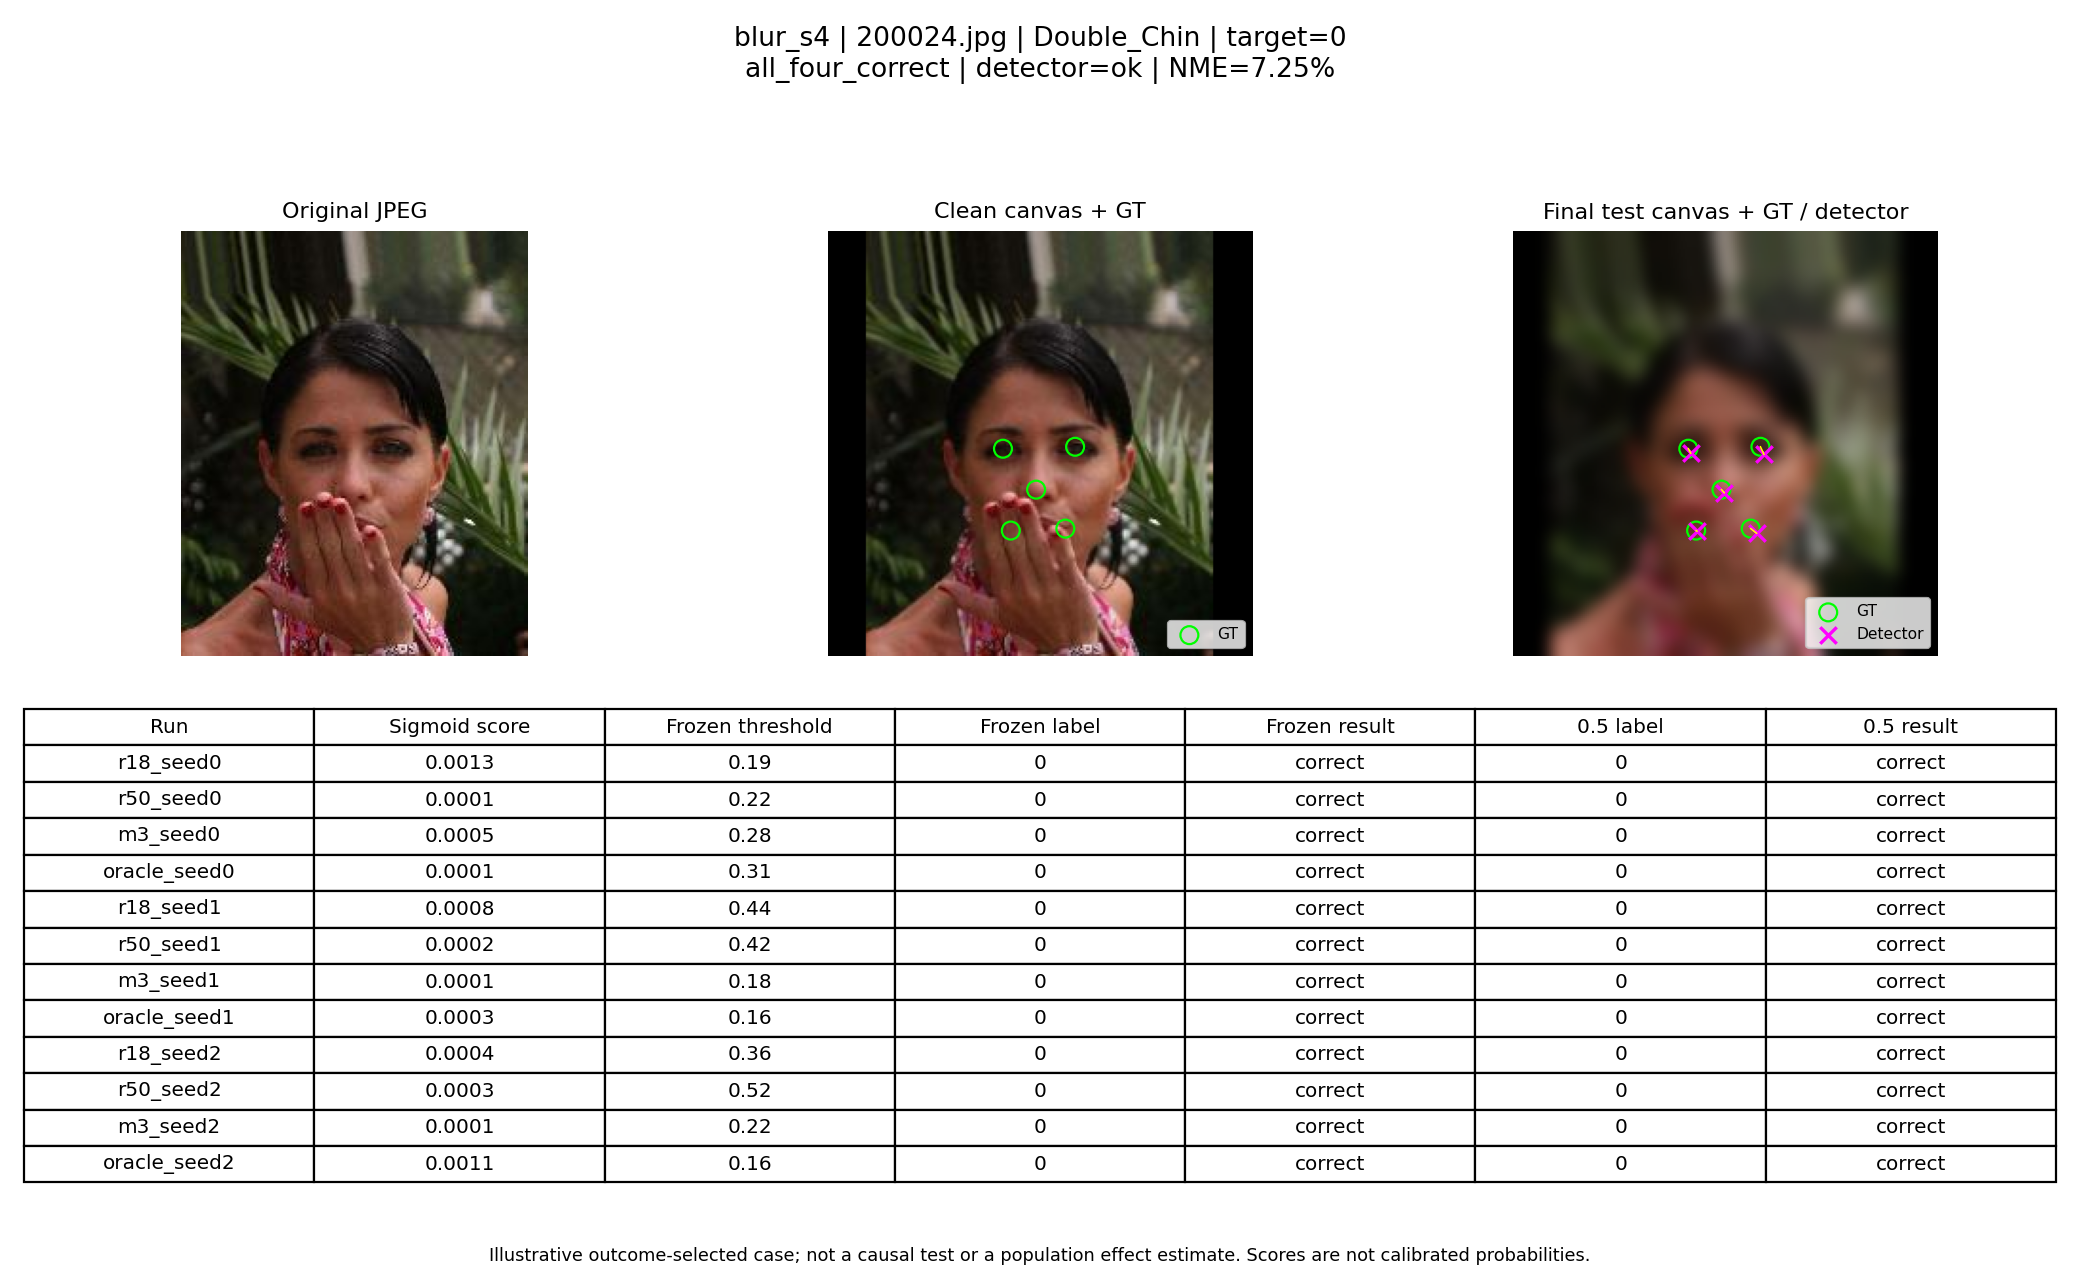

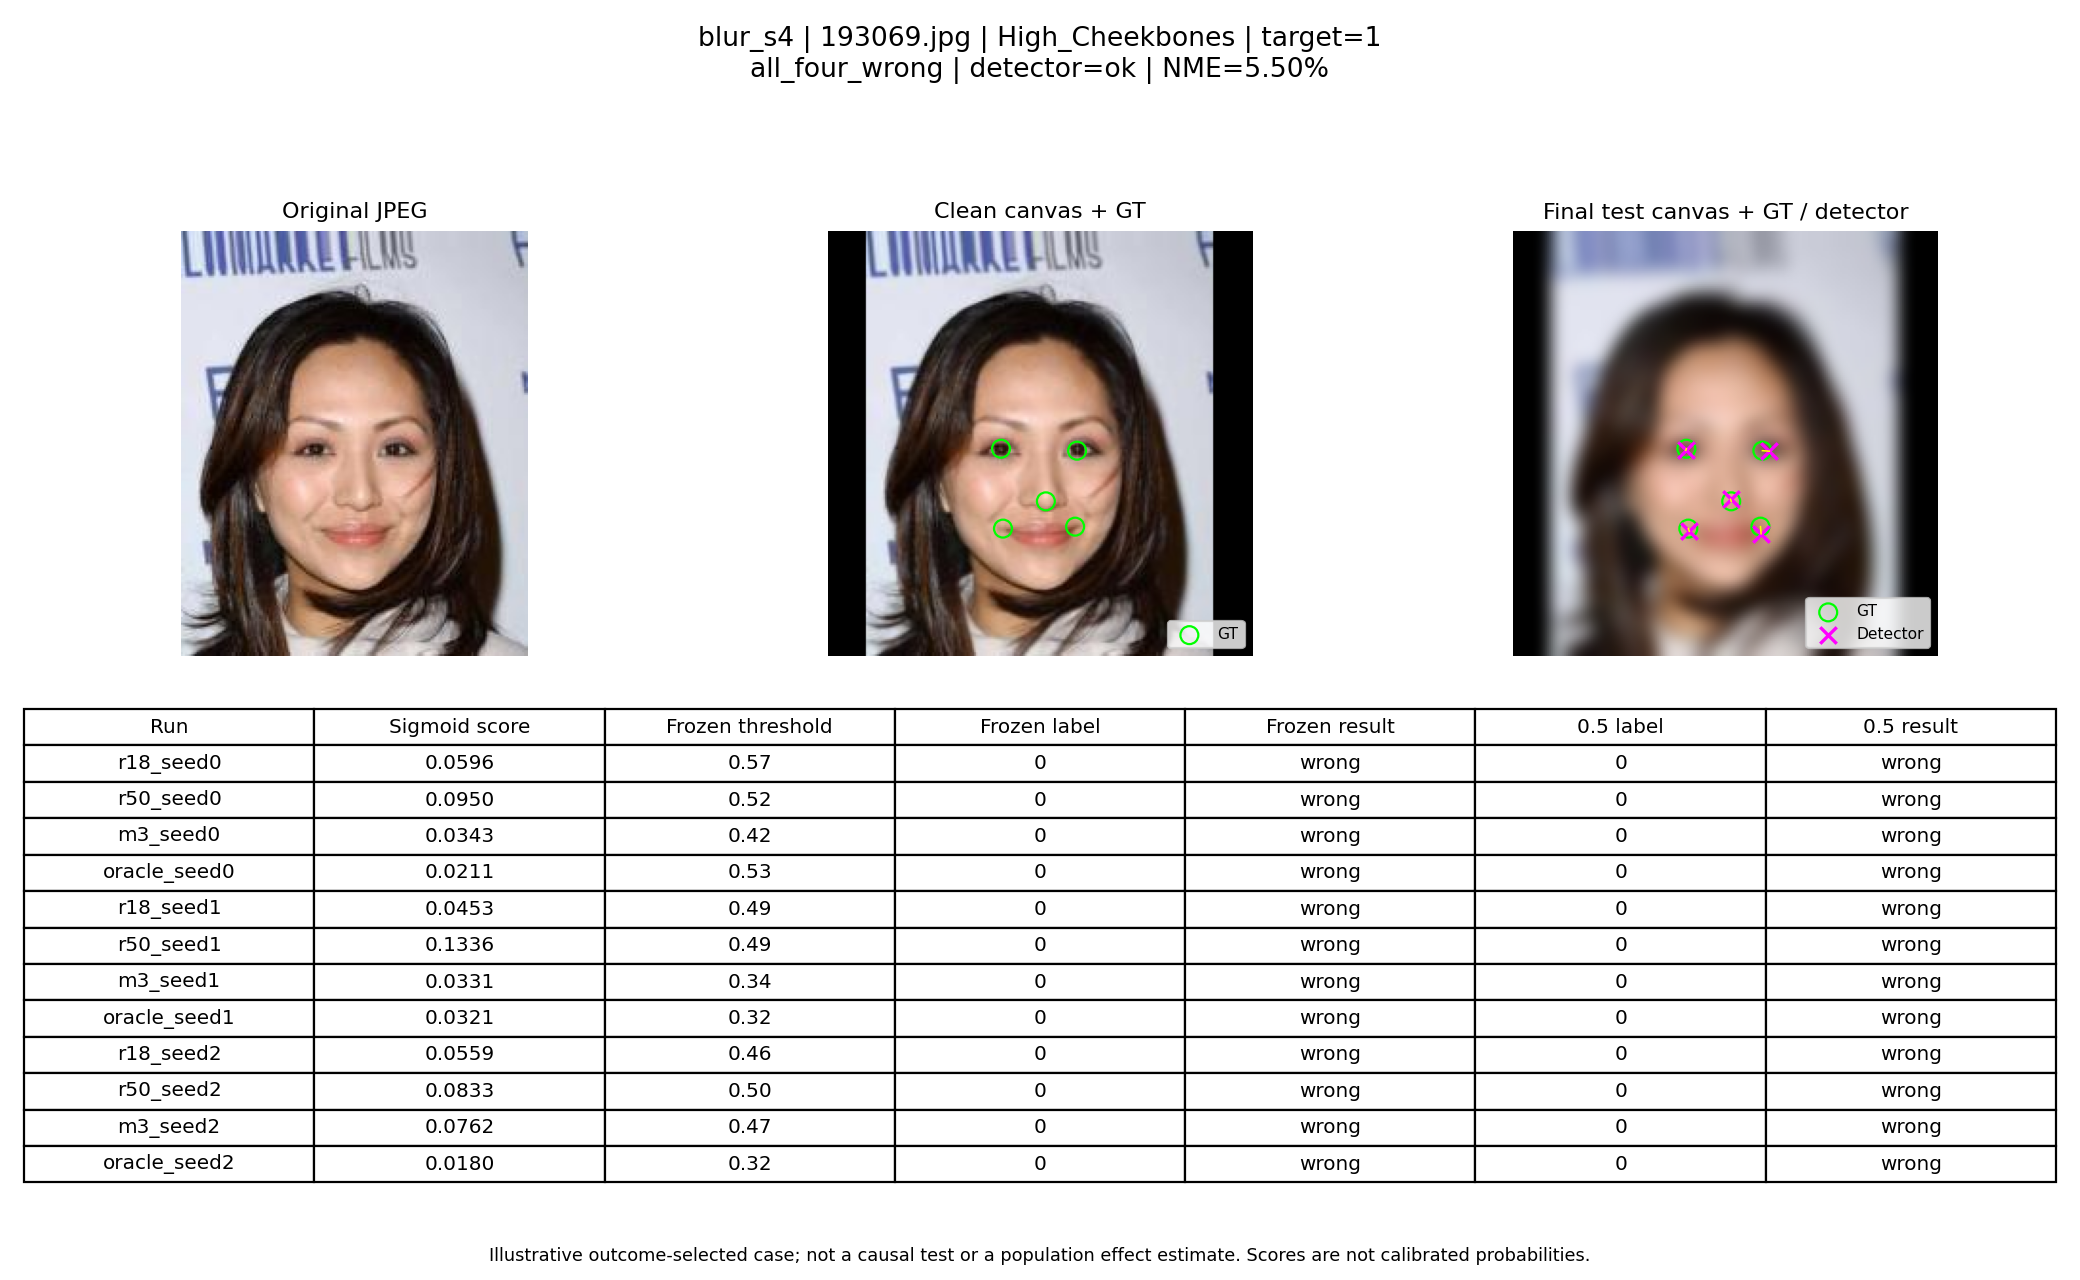

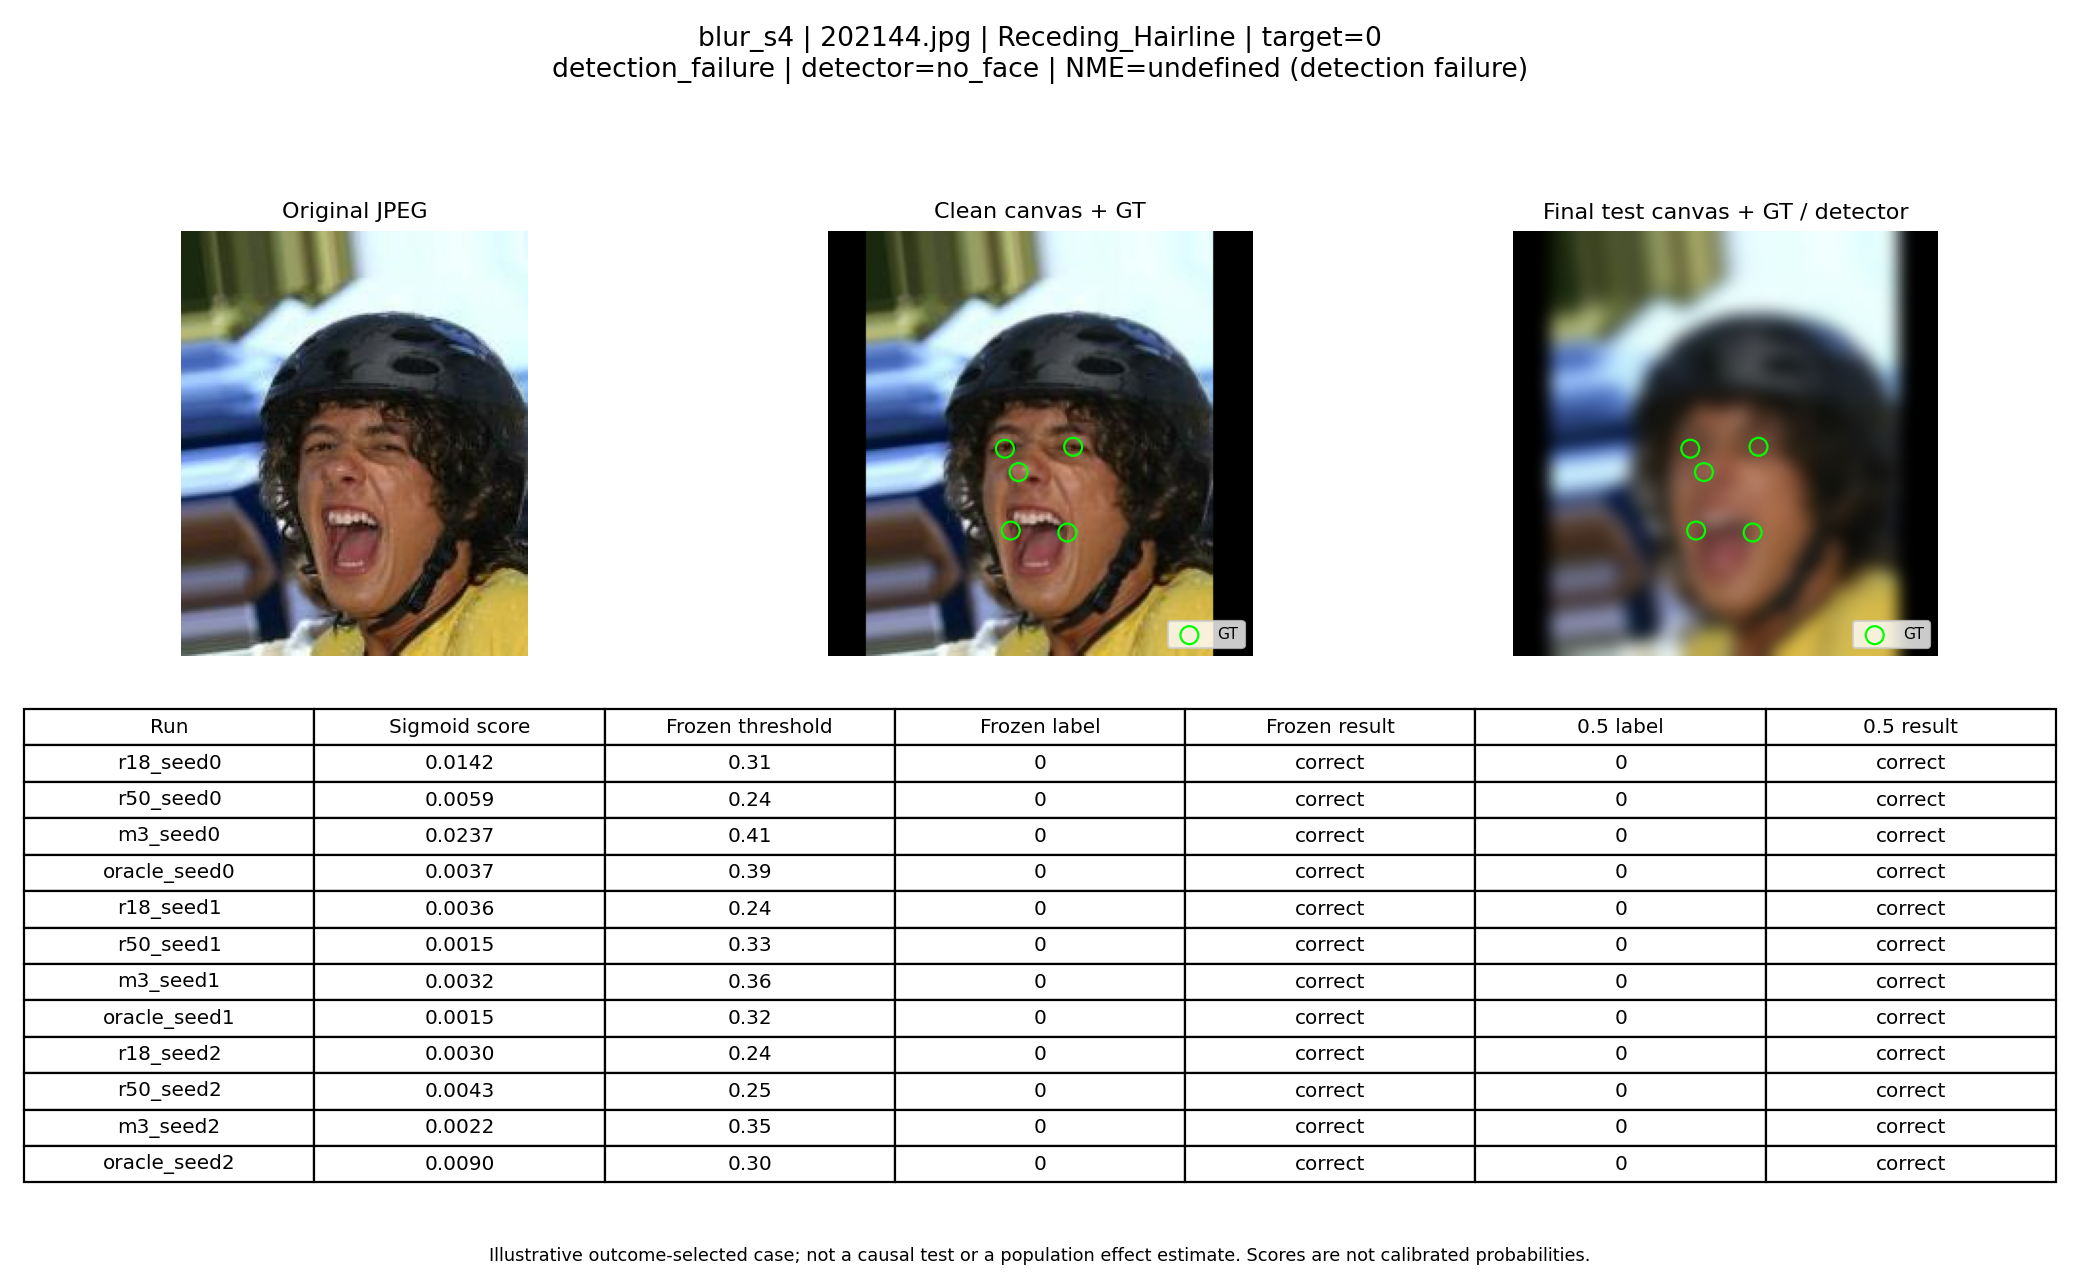

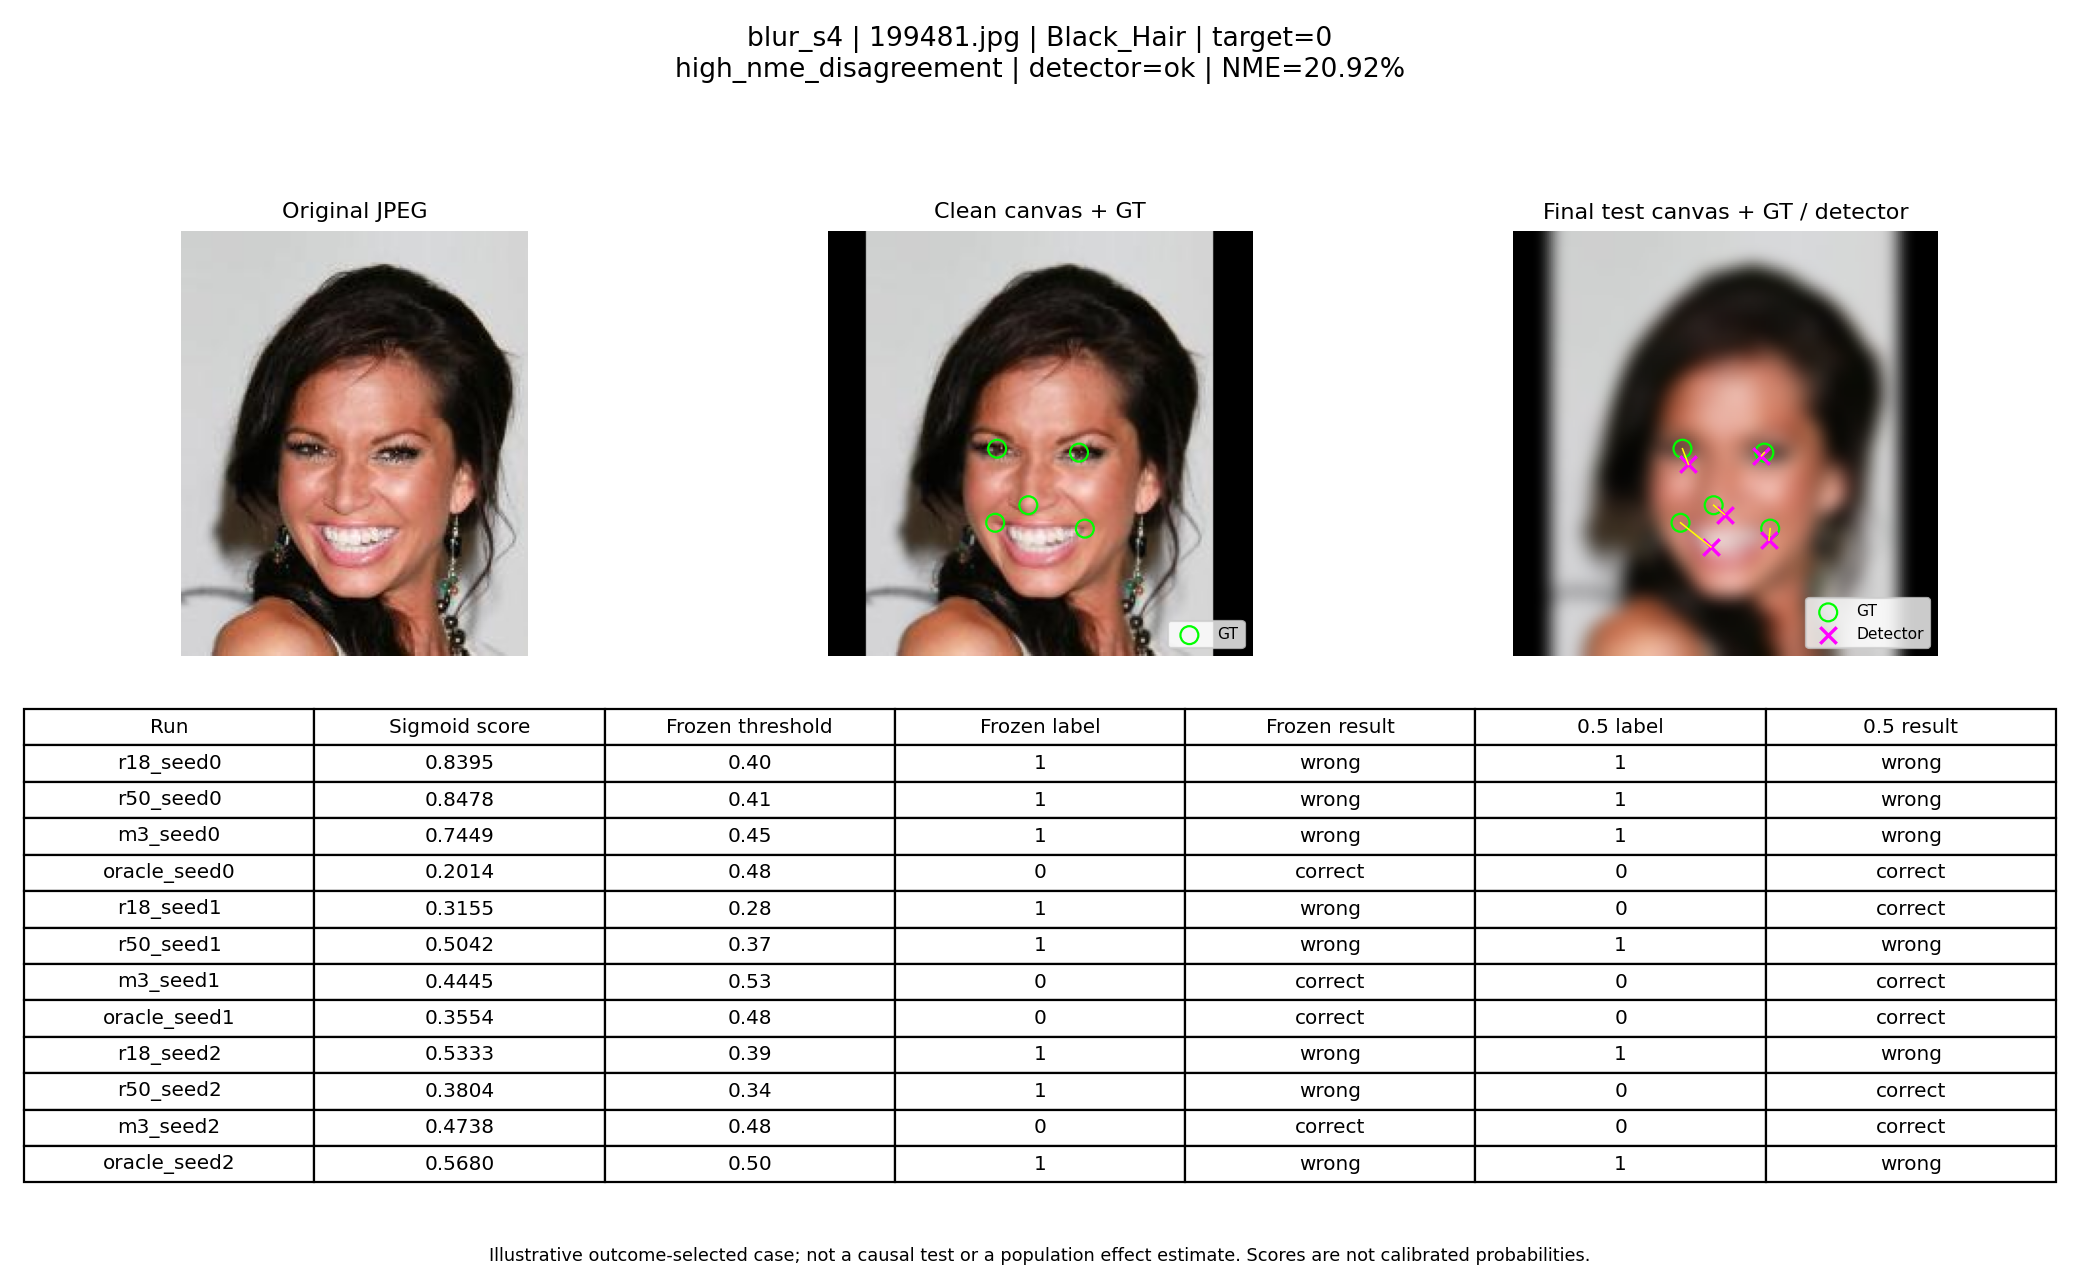

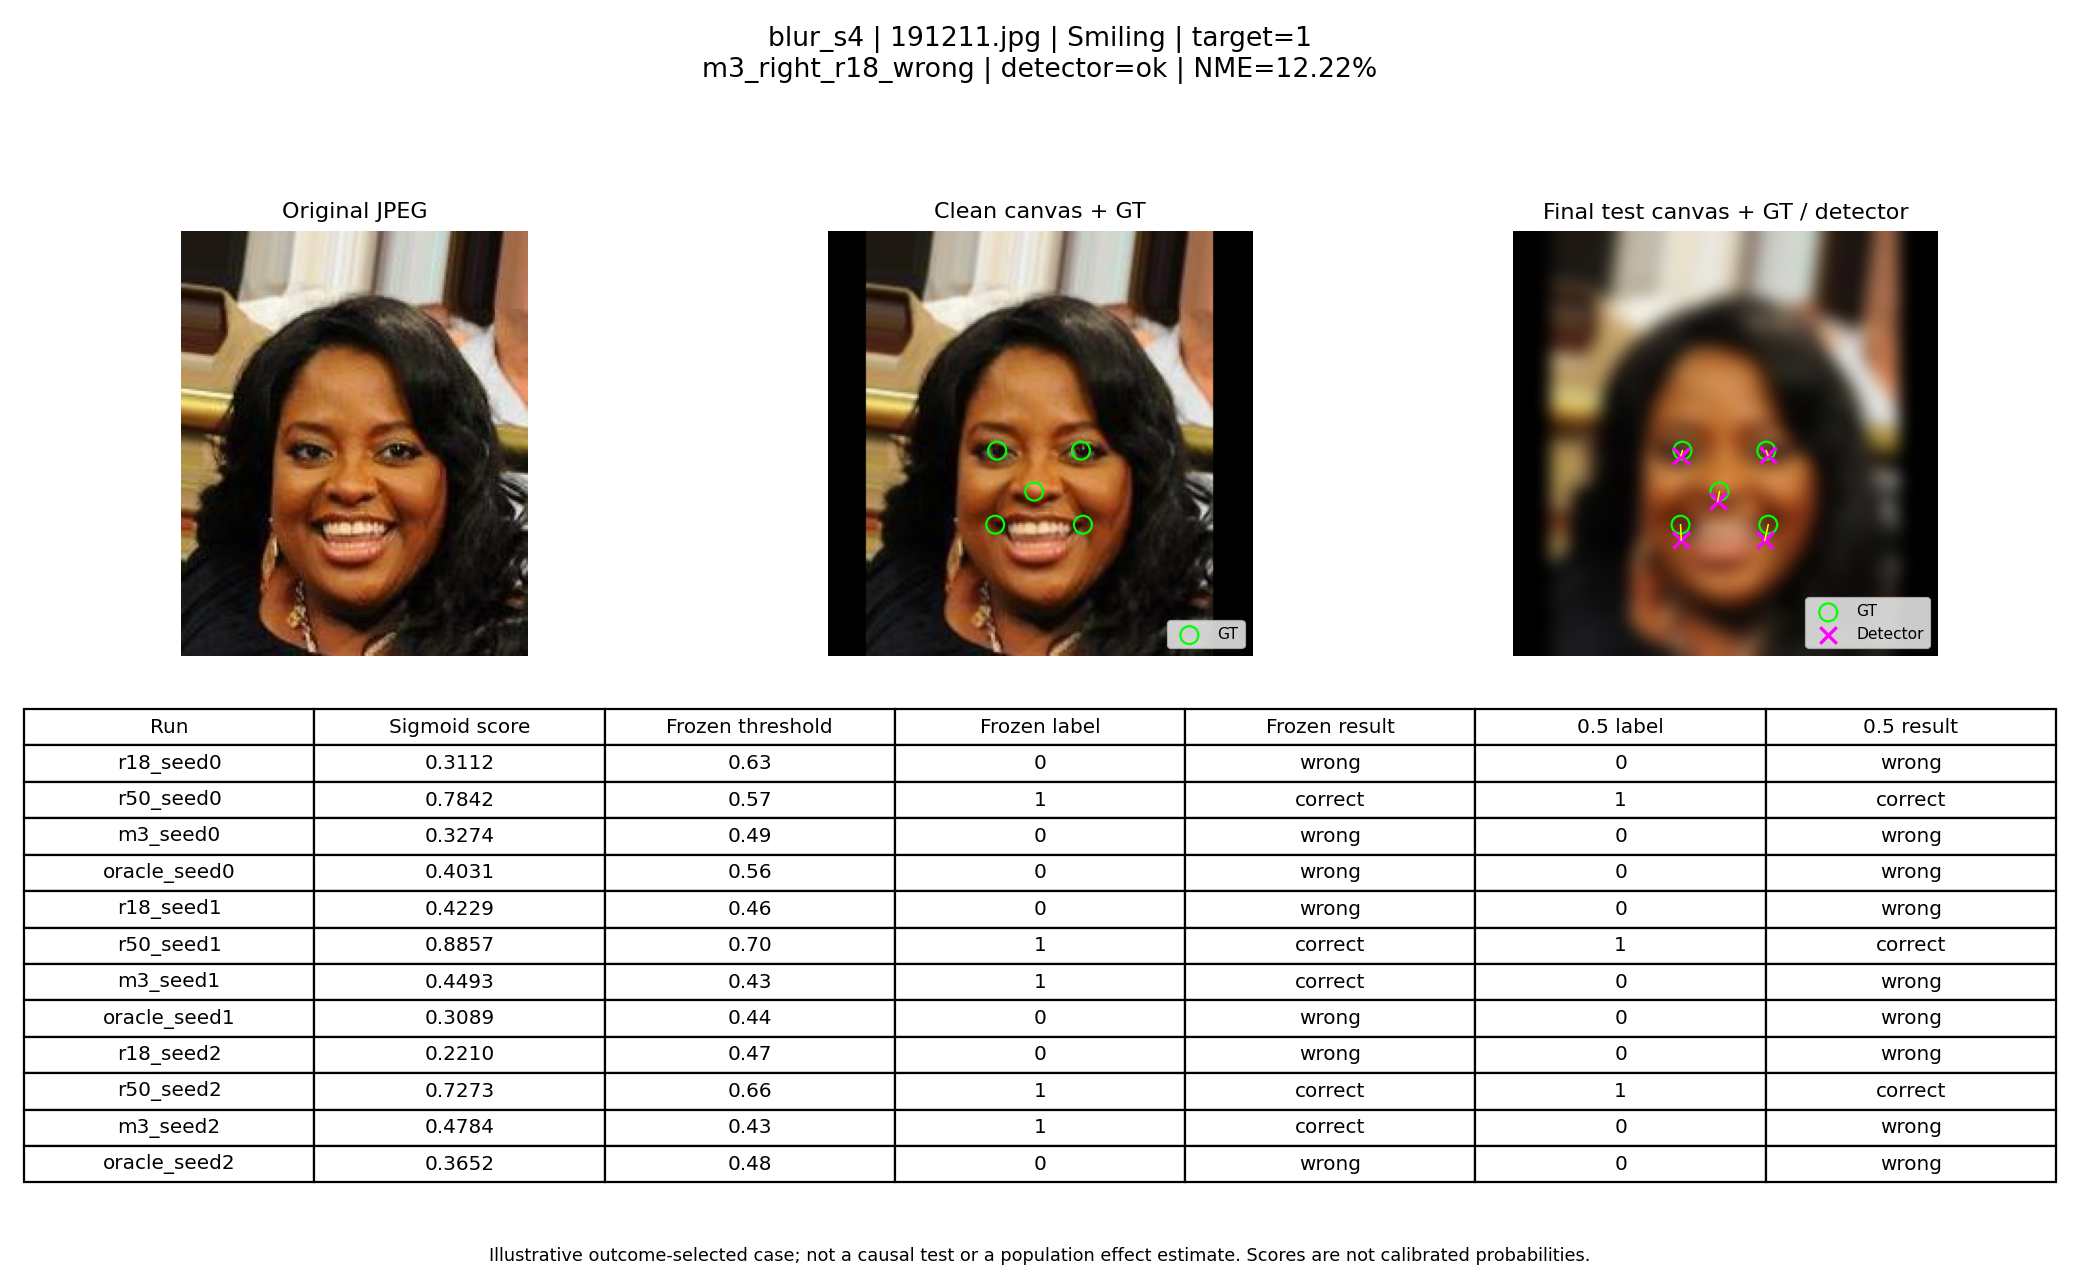

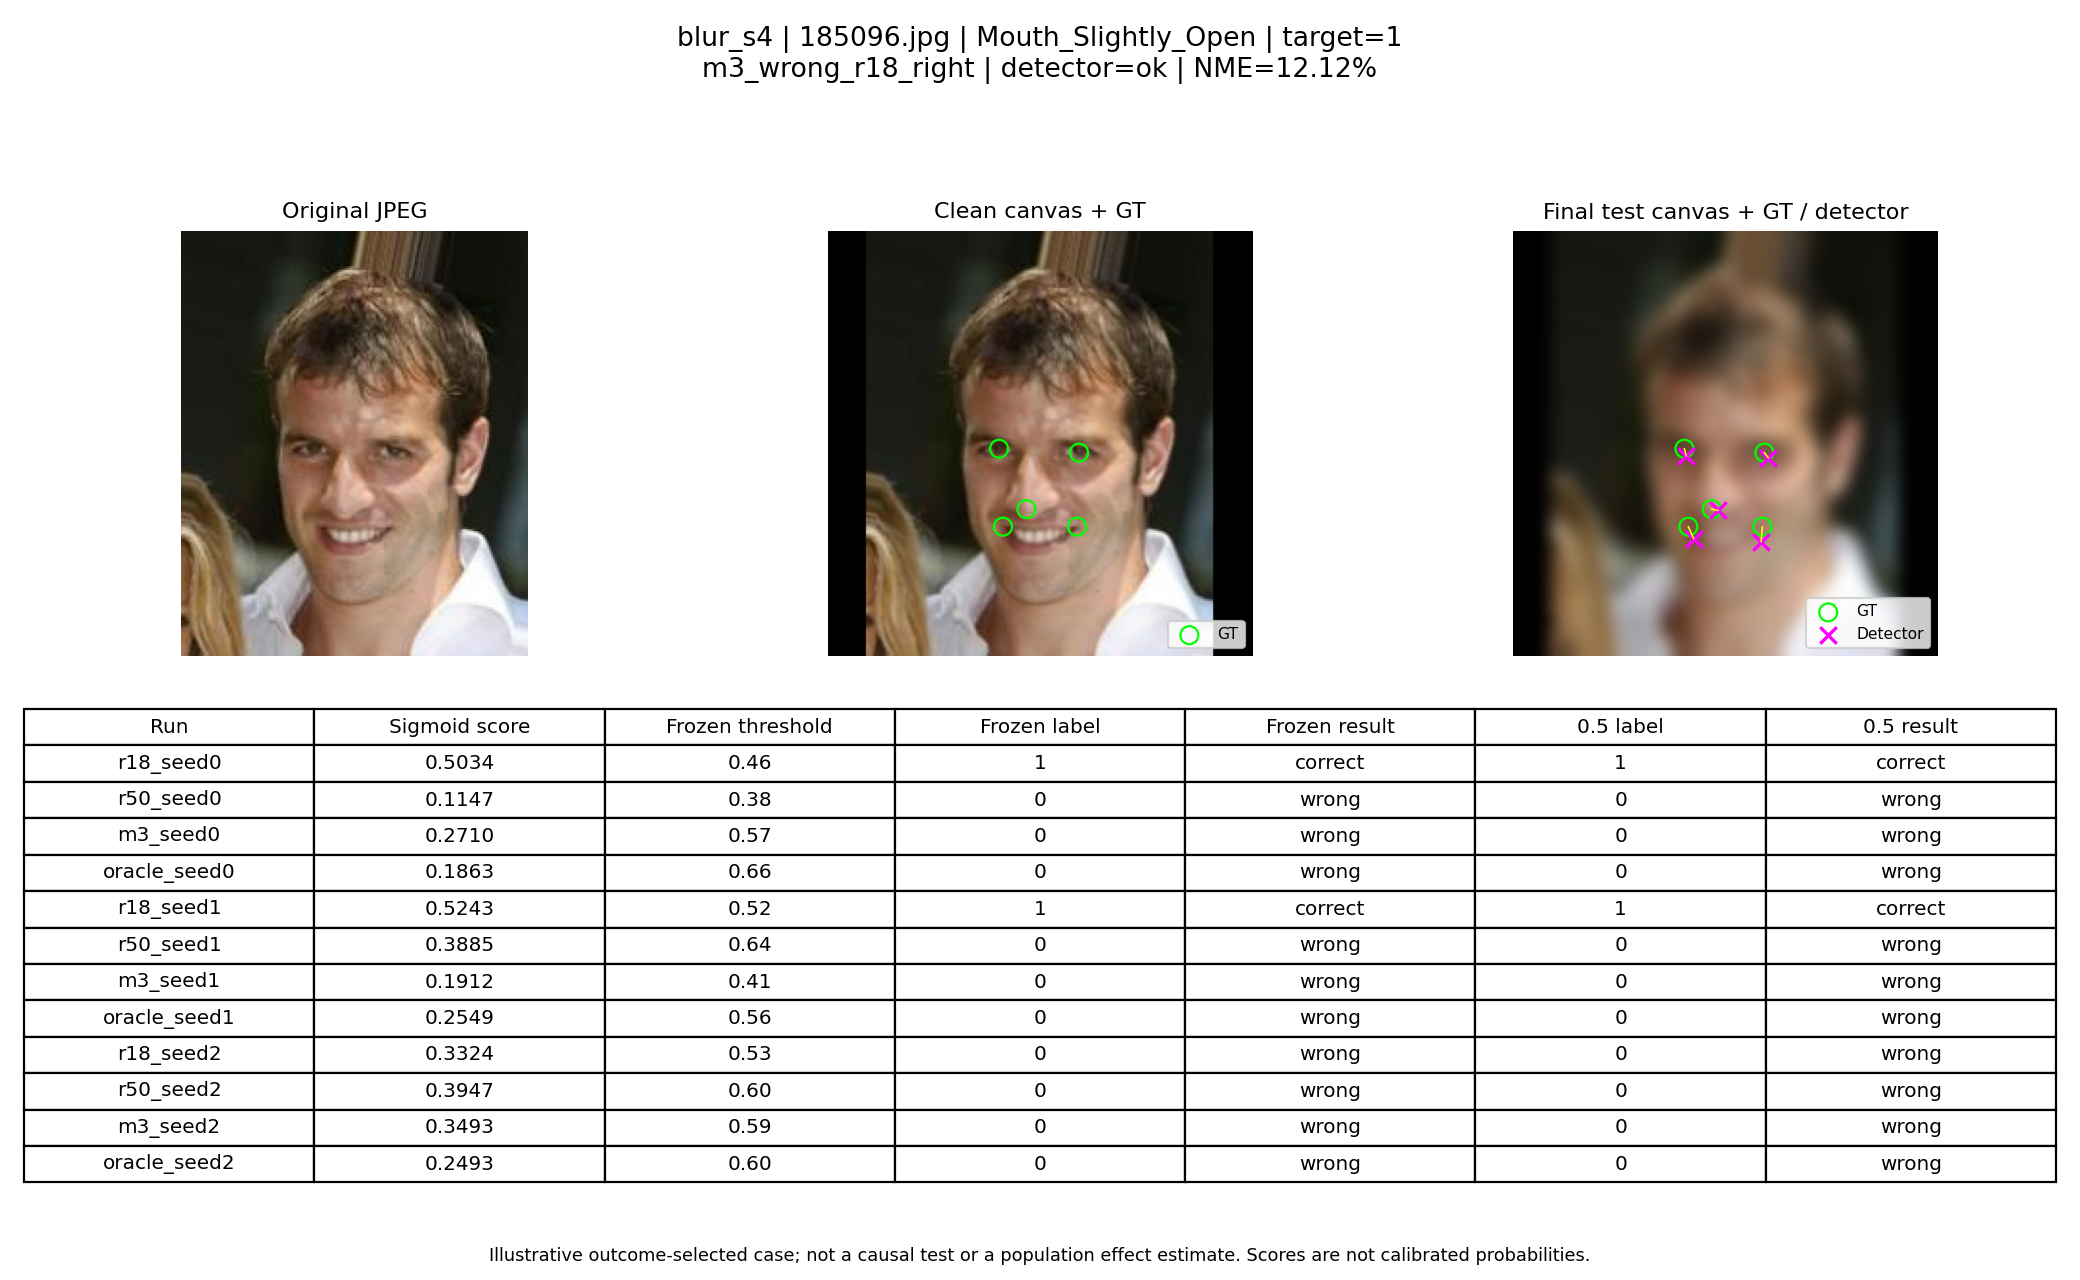

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Also download this executed notebook using File > Download > Download .ipynb


In [4]:
import json
from IPython.display import display, Image
from google.colab import files

completion = json.loads((RESULT_ROOT / 'completion_audit.json').read_text())
assert completion['complete'] and completion['all_rendered_inputs_verified']
print(json.dumps(completion, indent=2))
print('Preview: up to six case panels; all panels are in the archive')
for path in sorted((RESULT_ROOT / 'figures').glob('*.png'))[:6]:
    display(Image(filename=str(path)))
files.download(str(RESULT_ROOT / 'prediction_case_review_archive.zip'))
print('Also download this executed notebook using File > Download > Download .ipynb')
